<a href="https://colab.research.google.com/github/yuhui-0611/Unstructured-Data-Analysis/blob/main/UDA_Style_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Hugging Face에서 사전 학습된 ConvNeXtV2 모델과 전처리기를 불러와 이미지를 전처리하고, Train 데이터에서 특징 벡터를 추출하여 코사인 유사도로 유사 이미지를 확인한 다음, Backbone을 고정하고 FC Layer만 학습시켜 Validation 데이터로 최적 모델을 선택하고 Test 데이터로 최종 성능을 평가한 실습

# Inspect Pretrained Features

### Settings

In [ ]:
import torch
import random
import numpy as np

# settings
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PRETRAINED_MODEL = "facebook/convnextv2-base-22k-224"
SEED = 42

# hyper parameters
BATCH_SIZE = 32
WEIGHT_DECAY = 1e-2

# set seed
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print(f"DEVICE: {DEVICE}")
print(f"MODEL : {PRETRAINED_MODEL}")

DEVICE: cuda
MODEL : facebook/convnextv2-base-22k-224


### Data load & split

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

!unzip -q -o style_images.zip -d images

# 데이터 불러오기
df = pd.read_csv("style_annotations.csv")

# 데이터 split (70:15:15)
tr_val_df, te_df = train_test_split(
    df, test_size=0.15, random_state=SEED, stratify=df["style_label"]
)
tr_df, val_df = train_test_split(
    tr_val_df, test_size=0.15 / 0.85, random_state=SEED,
    stratify=tr_val_df["style_label"]
)

print(f"Train: {len(tr_df)}, Validation: {len(val_df)}, Test: {len(te_df)}")

Train: 210, Validation: 45, Test: 45


### Model load

In [ ]:
from transformers import AutoImageProcessor, AutoModelForImageClassification

# label 설정
classes = sorted(df["style_label"].unique())
label2id = {c: i for i, c in enumerate(classes)}
id2label = {i: c for c, i in label2id.items()}

# processor & model load
processor = AutoImageProcessor.from_pretrained(PRETRAINED_MODEL)

# pretrained model load
m = AutoModelForImageClassification.from_pretrained(
    PRETRAINED_MODEL,
    num_labels=len(classes),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
).to(DEVICE)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

[transformers] ConvNextV2ForImageClassification LOAD REPORT from: facebook/convnextv2-base-22k-224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 1024]) vs model:torch.Size([3, 1024])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([3])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


> 클래스별 숫자 라벨 설정 → 사전 학습된 전처리기 불러오기 → 사전 학습된 모델 불러오기

### Preprocess images

In [ ]:
from PIL import Image

# 모든 사진을 한 번만 전처리해서 tensor로 저장 (학습·평가에서 재사용)
data = {}
for split, d in [("train", tr_df), ("val", val_df), ("test", te_df)]:
    images = [Image.open(p).convert("RGB") for p in d["image_path"]]
    pixels = processor(images, return_tensors="pt")["pixel_values"]
    labels = torch.tensor(d["style_label"].map(label2id).values)
    data[split] = (pixels, labels)

print({split: tuple(x.shape) for split, (x, y) in data.items()})

{'train': (210, 3, 224, 224), 'val': (45, 3, 224, 224), 'test': (45, 3, 224, 224)}


> 이미지 불러오기 → RGB 변환 → 이미지 전처리 → 라벨을 숫자로 변환 → 학습·검증·테스트 데이터 저장

- from_pretrained()	: 사전 학습된 모델이나 이미지 전처리기를 불러옴
- processor() :	이미지 크기를 조정(resize)하고 정규화(normalize)하여 텐서로 변환

### show_similar() definition

In [ ]:
import matplotlib.pyplot as plt
import torch.nn.functional as F
from PIL import ImageOps

def show_similar(X, df, query, k=5):
    # query와 각 이미지의 cosine similarity 계산
    sims = F.cosine_similarity(X[query:query + 1], X)

    # 유사도가 높은 순서로 k+1개 선택 (첫 번째는 query 자신)
    top = sims.argsort(descending=True)[:k + 1].tolist()

    fig, axes = plt.subplots(1, k + 1, figsize=(2.2 * (k + 1), 3.6))
    for ax, i in zip(axes, top):
        img = Image.open(df["image_path"].iloc[i]).convert("RGB")
        ax.imshow(ImageOps.fit(img, (240, 320)))
        ax.set_title(f"{df['style_label'].iloc[i]}\n{sims[i]:.2f}")
        ax.axis("off")

    axes[0].set_title(f"Query: {df['style_label'].iloc[query]}")
    plt.tight_layout()
    plt.show()

> 스타일별로 Query 이미지를 한 장씩 선택 → 코사인 유사도 계산 → 유사도가 높은 이미지 k개 선택 → 시각화

### Extract features & similar photos

train features: (210, 1024)


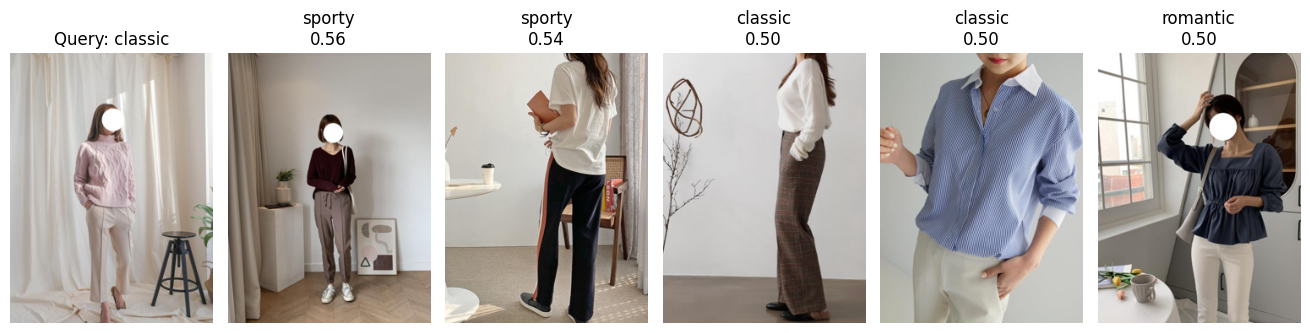

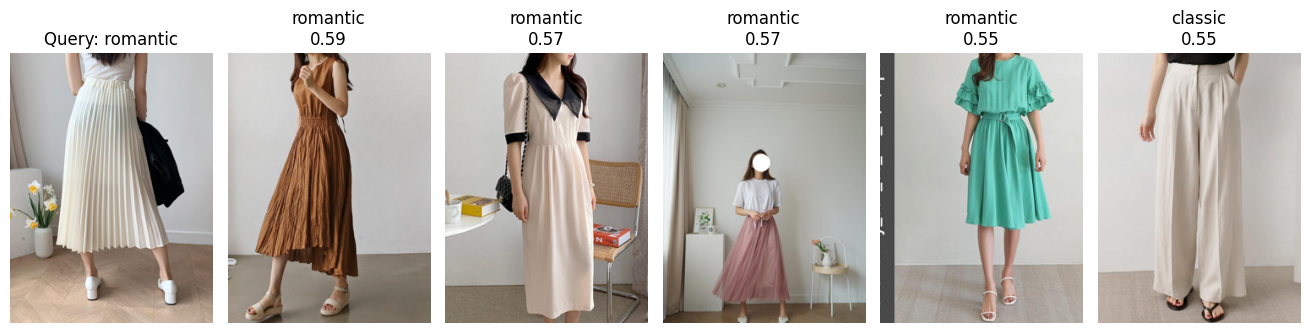

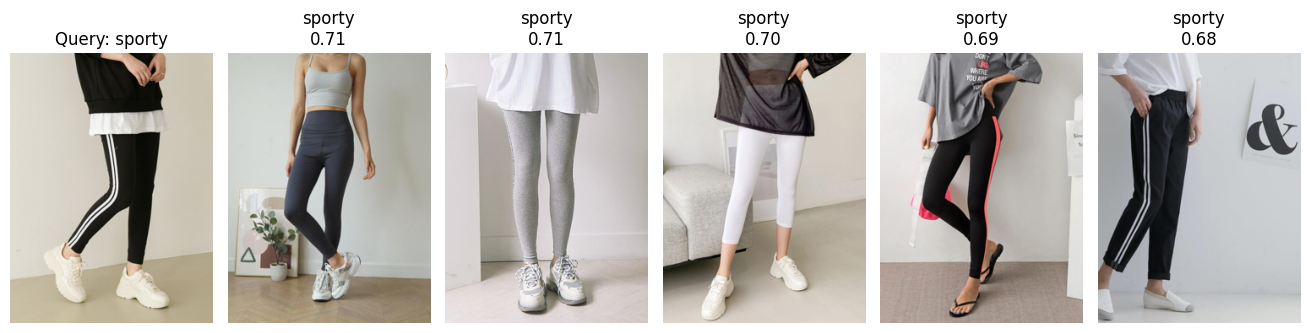

In [ ]:
# backbone(m.convnextv2)만 사용해 train 사진의 특징 추출 (학습 없음)
pixels, _ = data["train"]
m.eval()

with torch.no_grad():
    X_tr = m.convnextv2(pixel_values=pixels.to(DEVICE)).pooler_output

print("train features:", tuple(X_tr.shape))  # (이미지 수, 1024)

# train set 안에서 스타일별 query와 유사 이미지 확인
for style in classes:
    query = tr_df["style_label"].tolist().index(style)
    show_similar(X_tr, tr_df, query, k=5)

- m.convnextv2() : 분류기 이전의 Backbone만 사용하여 이미지별 특징 벡터 추출
- show_similar() : Query 이미지와 특징이 가장 유사한 이미지 k개를 시각화

> 사전 학습된 Backbone 사용 → 각 이미지에서 1,024차원 특징 벡터 추출 → 스타일별 Query 선택 → 가장 유사한 이미지 5개 출력

    - Backbone: 이미지의 시각적 특징을 추출하는 모델 부분
    - Feature vector: 이미지의 특징을 숫자로 표현한 벡터
    - Cosine similarity: 두 벡터의 방향이 얼마나 유사한지를 측정하는 지표 (1에 가까울수록 유사)
    - Query: 유사한 이미지를 검색할 때 기준이 되는 이미지

# FC Training & Evaluation

- predict() : 모델의 예측 결과 반환
- evaluate() : ACC, Precision, Recall, F1 및 Confusion Matrix 계산
- fit() : 모델 학습 및 Validation F1이 가장 높은 Epoch 선택

### predict(), evaluate() definition

In [16]:
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix

def predict(model, split):
    # gradient 없이 한 번에 예측 (사진 수가 적어 나눌 필요 없음)
    pixels, labels = data[split]
    model.eval()
    with torch.no_grad():
        logits = model(pixel_values=pixels.to(DEVICE)).logits
    return labels, logits.argmax(-1).cpu()

def evaluate(model, title):
    # test set 지표 계산 + confusion matrix
    trues, preds = predict(model, "test")
    metrics = {"ACC": accuracy_score(trues, preds)}
    for name, score in [("Prec", precision_score), ("Rec", recall_score),
                        ("F1", f1_score)]:
        metrics[name] = score(trues, preds, average="macro", zero_division=0)

    cm = confusion_matrix(trues, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes)
    plt.title(title); plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.show()
    return metrics

> 모델 예측 → 실제 라벨과 비교 → ACC, Precision, Recall, F1 계산 → Confusion Matrix 시각화

- model.eval() : 모델을 평가 모드로 전환
- torch.no_grad() : 기울기 계산 비활성화
- average="macro" : 클래스별 성능 지표를 각각 구한 뒤 동일한 가중치로 평균을 계산

### fit() definition

In [17]:
import copy

def fit(model, epochs, lr):
    # requires_grad=True인 파라미터만 학습
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=WEIGHT_DECAY)
    print(f"Trainable parameters: {sum(p.numel() for p in params):,}")
    pixels, labels = data["train"]
    best_f1 = -1

    for epoch in range(1, epochs + 1):
        # 학습: 매 epoch 순서를 섞고 mini-batch 단위로 업데이트
        model.train()
        order = torch.randperm(len(pixels))
        losses = []

        for i in range(0, len(pixels), BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            out = model(
                pixel_values=pixels[idx].to(DEVICE),
                labels=labels[idx].to(DEVICE)
            )
            optimizer.zero_grad()
            out.loss.backward()
            optimizer.step()
            losses.append(out.loss.item())

        # 검증: validation F1이 가장 높은 epoch의 모델 저장
        trues, preds = predict(model, "val")
        val_f1 = f1_score(trues, preds, average="macro")
        print(f"epoch {epoch:2d} | train loss {np.mean(losses):.4f} "
              f"| val F1 {val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1, best_epoch = val_f1, epoch
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    print(f"Best epoch: {best_epoch} | Validation F1: {best_f1:.4f}")

- out.loss.backward() : 역전파를 통해 기울기 계산
- optimizer.step() : 계산된 기울기를 이용해 파라미터 업데이트

### FC training (frozen backbone)

In [18]:
FC_EPOCHS = 20
FC_LR = 1e-3

# backbone 고정, FC layer만 학습
for p in m.convnextv2.parameters():
    p.requires_grad = False

fit(m, FC_EPOCHS, FC_LR)

Trainable parameters: 3,075
epoch  1 | train loss 0.9873 | val F1 0.6215
epoch  2 | train loss 0.5789 | val F1 0.5998
epoch  3 | train loss 0.4657 | val F1 0.6895
epoch  4 | train loss 0.3788 | val F1 0.6895
epoch  5 | train loss 0.3288 | val F1 0.7334
epoch  6 | train loss 0.2990 | val F1 0.7557
epoch  7 | train loss 0.2575 | val F1 0.7554
epoch  8 | train loss 0.2238 | val F1 0.7766
epoch  9 | train loss 0.2024 | val F1 0.7766
epoch 10 | train loss 0.1935 | val F1 0.7554
epoch 11 | train loss 0.1705 | val F1 0.7554
epoch 12 | train loss 0.1514 | val F1 0.7766
epoch 13 | train loss 0.1417 | val F1 0.7328
epoch 14 | train loss 0.1345 | val F1 0.7333
epoch 15 | train loss 0.1214 | val F1 0.7766
epoch 16 | train loss 0.1184 | val F1 0.7517
epoch 17 | train loss 0.1052 | val F1 0.7766
epoch 18 | train loss 0.1025 | val F1 0.7554
epoch 19 | train loss 0.0940 | val F1 0.7536
epoch 20 | train loss 0.0915 | val F1 0.7536
Best epoch: 8 | Validation F1: 0.7766


### Evaluation: FC training

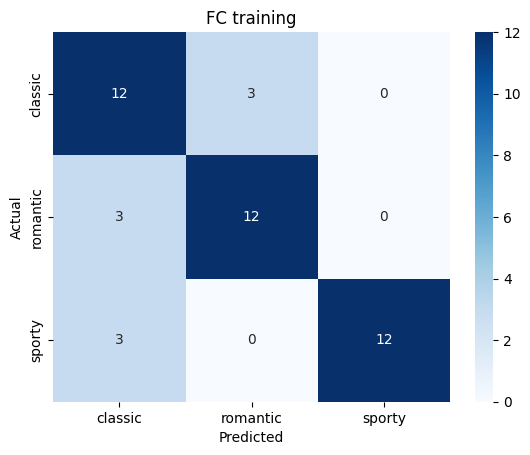

             ACC    Prec  Rec      F1
FC training  0.8  0.8222  0.8  0.8054


In [19]:
# test set으로 FC training 모델 평가
results = {"FC training": evaluate(m, "FC training")}
print(pd.DataFrame(results).T.round(4))

# Fine-tuning & Evaluation

### Fine-tuning (whole model)

In [20]:
FT_EPOCHS = 10
FT_LR = 1e-5

# backbone까지 모든 파라미터 학습 (FC training 모델에서 이어서 시작)
for p in m.parameters():
    p.requires_grad = True

fit(m, FT_EPOCHS, FT_LR)

Trainable parameters: 87,695,875
epoch  1 | train loss 0.2224 | val F1 0.7554
epoch  2 | train loss 0.1128 | val F1 0.7540
epoch  3 | train loss 0.0632 | val F1 0.7776
epoch  4 | train loss 0.0450 | val F1 0.7776
epoch  5 | train loss 0.0316 | val F1 0.7776
epoch  6 | train loss 0.0226 | val F1 0.7776
epoch  7 | train loss 0.0171 | val F1 0.7776
epoch  8 | train loss 0.0138 | val F1 0.7776
epoch  9 | train loss 0.0114 | val F1 0.7776
epoch 10 | train loss 0.0098 | val F1 0.7776
Best epoch: 3 | Validation F1: 0.7776


### Evaluation: fine-tuning & comparison

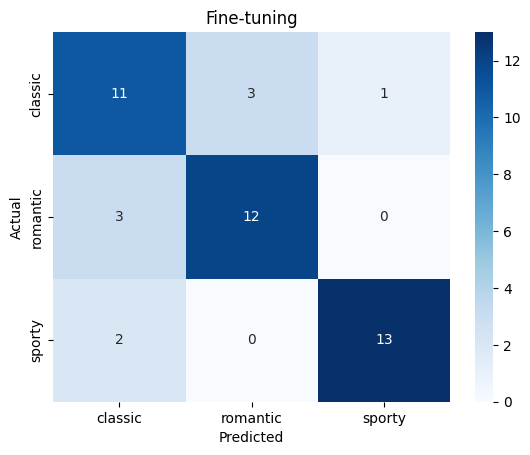

             ACC    Prec  Rec      F1
FC training  0.8  0.8222  0.8  0.8054
Fine-tuning  0.8  0.8054  0.8  0.8021


In [21]:
# test set으로 fine-tuning 모델 평가 후 두 모델 비교
results["Fine-tuning"] = evaluate(m, "Fine-tuning")
print(pd.DataFrame(results).T.round(4))

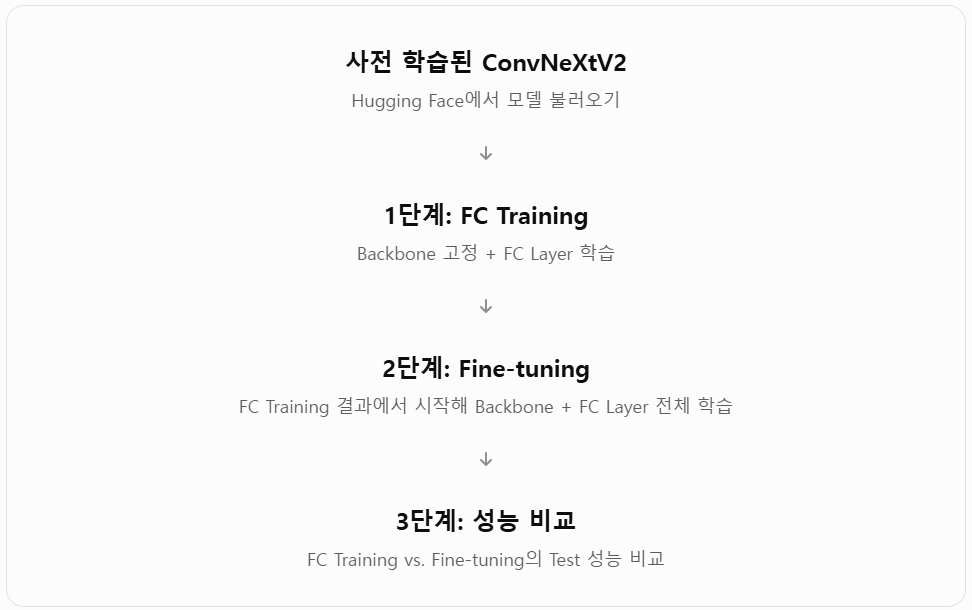

## FC Training과 Fine-tuning 비교

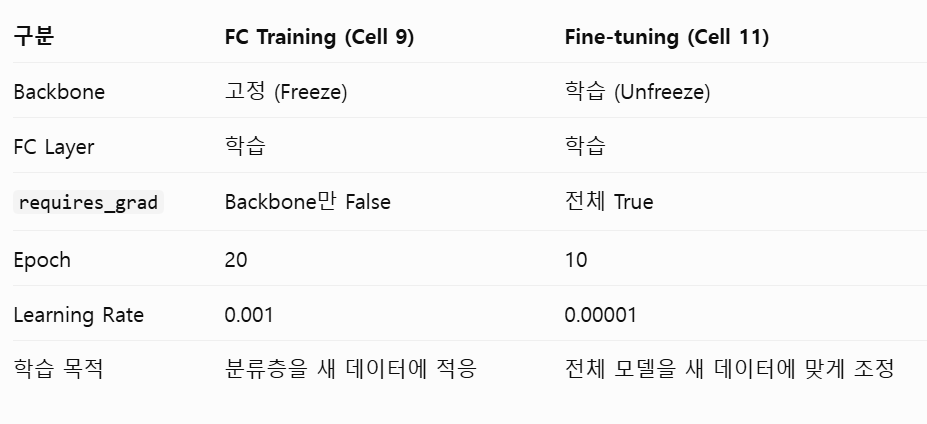